## Importing Libaries and Data

In [83]:
from sympy import *
import numpy as np
import matplotlib.pyplot as plt
from helpers import *
from implementations import *

In [84]:
x_train, x_test, y_train, train_ids, test_ids = load_csv_data("dataset")
y_train[y_train == -1] = 0 # format for logistic regression

In [85]:
feature_names = np.genfromtxt("dataset/x_train.csv", delimiter=",", dtype=str, max_rows=1)
feature_names = feature_names[1:]

## Splitting the Data & Handeling Missing Values

#### Splitting the training data into a training and a test set

In [86]:
def split_data(x, y, ratio, seed=1):
    """
    Args:
        x: numpy array of shape (N,), N is the number of samples.
        y: numpy array of shape (N,).
        ratio: scalar in [0,1]
        seed: integer.

    Returns:
        x_tr: numpy array containing the train data.
        x_te: numpy array containing the test data.
        y_tr: numpy array containing the train labels.
        y_te: numpy array containing the test labels.
    """
    # set seed
    np.random.seed(seed)
    N = x.shape[0]

    shuffled_indices = np.random.permutation(N)
    cutoff = int(np.floor(ratio * N))

    train_indices = shuffled_indices[:cutoff]
    test_indices = shuffled_indices[cutoff:]

    x_tr, x_te = x[train_indices], x[test_indices]
    y_tr, y_te = y[train_indices], y[test_indices]

    return x_tr, x_te, y_tr, y_te

x_tr, x_te, y_tr, y_te = split_data(x_train, y_train, 0.8, seed=1)

#### Exploring missing values for each feature

In [87]:
def replace_sentinels(x, names, rules):
    """Return a copy of x with sentinel codes replaced by NaN (or by a real value)."""
    x = x.copy()
    for j, name in enumerate(names):
        r = rules.get(name)
        if r is None:
            continue
        for old, new in r.items():
            x[x[:, j] == old, j] = new
    return x

nan = np.nan

# describes how the interview was done
admin = ["FMONTH", "IMONTH", "IYEAR", "DISPCODE", "QSTVER", "QSTLANG", "MSCODE", "_RAWRAKE"]

# groups of columns that share the same codes (BRFSS 2015: 7 = don't know, 9 = refused)
yes_no_7_9 = ["GENHLTH", "HLTHPLN1", "PERSDOC2", "MEDCOST", "CHECKUP1", "BPHIGH4", "BPMEDS",
              "BLOODCHO", "CHOLCHK", "TOLDHI2", "CVDSTRK3", "ASTHMA3", "ASTHNOW", "CHCSCNCR",
              "CHCOCNCR", "CHCCOPD1", "HAVARTH3", "ADDEPEV2", "CHCKIDNY", "DIABETE3",
              "RENTHOM1", "VETERAN3", "INTERNET", "QLACTLM2", "USEEQUIP", "BLIND", "DECIDE",
              "DIFFWALK", "DIFFDRES", "DIFFALON", "SMOKE100", "SMOKDAY2", "USENOW3",
              "EXERANY2", "STRENGTH", "SEATBELT", "FLUSHOT6", "PNEUVAC3", "HIVTST6",
              "PDIABTST", "PREDIAB1", "INSULIN", "ARTHDIS2", "LMTJOIN3", "MARITAL",
              "EDUCA", "EMPLOY1", "PREGNANT"]

rules = {name: {7: nan, 9: nan} for name in yes_no_7_9}

# "none" is coded 88 (a real value, zero), don't know = 77, refused = 99
for name in ["PHYSHLTH", "MENTHLTH", "POORHLTH"]:
    rules[name] = {88: 0, 77: nan, 99: nan}
rules["CHILDREN"] = {88: 0, 99: nan}
rules["AVEDRNK2"] = {88: 0, 77: nan, 99: nan}
rules["MAXDRNKS"] = {88: 0, 77: nan, 99: nan}
rules["DRNK3GE5"] = {88: 0, 77: nan, 99: nan}

# other special cases
rules["INCOME2"]  = {77: nan, 99: nan}
rules["DIABAGE2"] = {98: nan, 99: nan}
rules["ALCDAY5"]  = {777: nan, 999: nan, 888: 0}
rules["WEIGHT2"]  = {7777: nan, 9999: nan}
rules["HEIGHT3"]  = {7777: nan, 9999: nan}

# calculated (underscore) variables: 9 means don't know / refused / missing
derived_9 = ["_RFHLTH", "_HCVU651", "_RFHYPE5", "_CHOLCHK", "_RFCHOL", "_LTASTH1", "_CASTHM1",
             "_RACE", "_RACEGR3", "_RFBMI5", "_EDUCAG", "_INCOMG", "_SMOKER3", "_RFSMOK3",
             "_RFBING5", "_RFDRHV5", "_TOTINDA", "_PACAT1", "_PAINDX1", "_PA150R2",
             "_PA300R2", "_PASTRNG", "_PAREC1", "_PASTAE1", "_LMTACT1", "_LMTWRK1",
             "_LMTSCL1", "_RFSEAT2", "_RFSEAT3", "_FLSHOT6", "_PNEUMO2", "_AIDTST3", "PAMISS1_"]
for name in derived_9:
    rules[name] = {9: nan}
rules["_AGEG5YR"] = {14: nan}
rules["_AGE65YR"] = {3: nan}
rules["_AGE_G"]   = {}

x_tr = replace_sentinels(x_tr, feature_names, rules)
x_te = replace_sentinels(x_te, feature_names, rules)

In [88]:
fraction_missing = np.isnan(x_tr).mean(axis=0)
keep = fraction_missing < 0.6 # we drop any columns with more than 60% missing values
keep = keep & ~np.isin(feature_names, admin)

x_tr = x_tr[:, keep]
x_te = x_te[:, keep]
kept_names = feature_names[keep]

median = np.nanmedian(x_tr, axis=0)
x_tr = np.where(np.isnan(x_tr), median, x_tr)
x_te = np.where(np.isnan(x_te), median, x_te)

#### Standardize from training data

In [89]:
mean = x_tr.mean(axis=0)
std = x_tr.std(axis=0)
std[std == 0] = 1

x_tr = (x_tr - mean) / std
x_te = (x_te - mean) / std

#### Adding a bias column (intercept term, w0)

In [90]:
x_tr = np.c_[np.ones(x_tr.shape[0]), x_tr]
x_te = np.c_[np.ones(x_te.shape[0]), x_te]

feature_name_list = np.array(["bias"] + list(kept_names))

## Exploratory Analysis

In [91]:
N = y_tr.shape[0] + y_te.shape[0] 
total_disease = (y_tr == 1).sum() + (y_te == 1).sum()

print(f"Percentage of Patients with MICHD in the training set: {total_disease / N * 100:.2f} %")

Percentage of Patients with MICHD in the training set: 8.83 %


## Implementing Regularized Logistic Regression

In [92]:
y_tr = y_tr.reshape(-1, 1)
y_te = y_te.reshape(-1, 1)

#### Finding the best learning rate (gamma)

In [93]:
initial_w = np.zeros((x_tr.shape[1], 1))
max_iters = 100
lambda_ = 0
gammas = [1, 1.25, 1.5, 1.75, 2]

min_loss = np.inf
best_gamma = None

for gamma in gammas:
    w, loss = reg_logistic_regression(y_tr, x_tr, lambda_, initial_w, max_iters, gamma)
    if min_loss > loss:
        min_loss = loss
        best_gamma = gamma
    print(f"gamma = {gamma:<8} loss = {loss:.4f}")

print(f"Smallest Loss ={min_loss: .2f} Best gamma = {best_gamma}")

gamma = 1        loss = 0.2237
gamma = 1.25     loss = 0.2234
gamma = 1.5      loss = 0.2240
gamma = 1.75     loss = 0.2473
gamma = 2        loss = 0.2746
Smallest Loss = 0.22 Best gamma = 1.25


#### Finding the best hyperparameter (lambda)

In [94]:
lambdas = [0, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2]

losses_tr, losses_te = [], []
w_list = []

for lam in lambdas:
    w, loss_tr = reg_logistic_regression(y_tr, x_tr, lam, initial_w, max_iters, best_gamma)
    loss_te = (1/len(y_te)) * np.sum(-y_te * (x_te @ w) + np.log(1 + np.exp(x_te @ w)))

    w_list.append(w)
    losses_tr.append(loss_tr)
    losses_te.append(loss_te)

    print(f"lambda = {lam:<8} train = {loss_tr:.4f} test = {loss_te:.4f}")

index = int(np.argmin(losses_te))
best_lambda = lambdas[index]
best_w_1 = w_list[index]
print("best lambda:", best_lambda)

lambda = 0        train = 0.2234 test = 0.2198
lambda = 1e-06    train = 0.2234 test = 0.2198
lambda = 1e-05    train = 0.2234 test = 0.2198
lambda = 0.0001   train = 0.2234 test = 0.2198
lambda = 0.001    train = 0.2235 test = 0.2199
lambda = 0.01     train = 0.2247 test = 0.2209
best lambda: 0


## Feature Interaction Model

#### Finding the model influential Features

In [95]:
# Use only the m most influential features
m = 20
best_w = best_w_1.ravel()
feature_name_list = feature_name_list.ravel()

strengths = []
for col in range(1, len(best_w)):
    strengths.append((abs(best_w[col]), col)) # the strength of a feature’s weight, that feature’s column number

strengths.sort(reverse=True)

top_features = []
for strength, col in strengths[:m]:
    top_features.append(col)
    print(f"{feature_name_list[col]:<12} weight = {best_w[col]:+.3f}")

SEX          weight = -0.357
GENHLTH      weight = +0.339
_AGEG5YR     weight = +0.261
_AGE80       weight = +0.260
CVDSTRK3     weight = -0.179
CHOLCHK      weight = -0.145
_RFHYPE5     weight = +0.138
CHCCOPD1     weight = -0.132
_RFCHOL      weight = +0.132
TOLDHI2      weight = -0.132
BPHIGH4      weight = -0.131
PNEUVAC3     weight = -0.130
SMOKE100     weight = -0.097
CHCKIDNY     weight = -0.081
BPMEDS       weight = -0.080
DIABETE3     weight = -0.080
MEDCOST      weight = -0.070
_AGE_G       weight = +0.067
QLACTLM2     weight = -0.066
BLOODCHO     weight = -0.061


#### Creating potential interaction features

In [96]:
# Candidate terms
candidates = []

# Pairwise interactions between the top features
for a in range(len(top_features)):
    for b in range(a + 1, len(top_features)):
        candidates.append((top_features[a], top_features[b]))

# Squares of top features
# Skip features with only 2 distinct values, since the square of a binary feature carries no new information
for col in top_features:
    if len(np.unique(x_tr[:, col])) > 2:
        candidates.append((col, col))

# Readable names for the report
def term_name(pair):
    i, j = pair
    if i == j:
        return f"{feature_name_list[i]}^2"
    return f"{feature_name_list[i]} x {feature_name_list[j]}"

#### Selecting the interaction features

In [97]:
# Selection of Features
def make_terms(x, pairs, stats=None):
    X = np.column_stack([x[:, i] * x[:, j] for i, j in pairs])
    if stats is None:                       # fit on training data only
        stats = (X.mean(axis=0), X.std(axis=0) + 1e-12)
    return (X - stats[0]) / stats[1], stats

C_tr, stats = make_terms(x_tr, candidates)
C_te, _ = make_terms(x_te, candidates, stats)

def val_loss(y, X, w):
    z = X @ w
    return np.mean(-y * z + np.logaddexp(0, z))

lam, gamma, iters = best_lambda, best_gamma, 200 # warm start, so fewer iterations are needed
batch = 3
tol = 1e-10 # tolerance, minimum improvement to accept a step

X_tr, X_te = x_tr, x_te
w = best_w.reshape(-1, 1) # trained on x_tr (with bias)
best_val = val_loss(y_te, X_te, w)
remaining = list(range(C_tr.shape[1]))
selected = []
history = [best_val]

while remaining:
    # score each remaining candidate by how strongly it correlates with the residual
    resid = (sigmoid(X_tr @ w) - y_tr).ravel()
    scores = np.abs(C_tr[:, remaining].T @ resid) / len(resid)
    order = np.argsort(scores)[::-1][:batch]
    new = [remaining[k] for k in order]

    # add them and refit, starting from the current weights
    X_tr_new = np.c_[X_tr, C_tr[:, new]]
    X_te_new = np.c_[X_te, C_te[:, new]]
    w_init = np.vstack([w, np.zeros((len(new), 1))])
    w_new, _ = reg_logistic_regression(y_tr, X_tr_new, lam, w_init, iters, gamma)
    v = val_loss(y_te, X_te_new, w_new)

    if v < best_val - tol: # we accept the feature if its loss is smaller
        X_tr, X_te, w, best_val = X_tr_new, X_te_new, w_new, v
        selected += new
        remaining = [r for r in remaining if r not in new]
        history.append(v)
        print(f"added {[term_name(candidates[k]) for k in new]}  val loss = {v:.5f}")
    else:
        break

added ['CVDSTRK3 x TOLDHI2', 'CVDSTRK3 x _RFCHOL', '_AGEG5YR x CVDSTRK3']  val loss = 0.21925
added ['CVDSTRK3 x SMOKE100', 'GENHLTH x CVDSTRK3', 'CVDSTRK3 x BPHIGH4']  val loss = 0.21924
added ['_AGEG5YR x CHCCOPD1', '_AGE80 x CHCCOPD1', '_RFCHOL x DIABETE3']  val loss = 0.21900
added ['_AGEG5YR x BPHIGH4', '_AGEG5YR x _RFHYPE5', '_AGE80 x BPHIGH4']  val loss = 0.21879
added ['SEX x GENHLTH', 'SEX x _RFCHOL', 'SEX x TOLDHI2']  val loss = 0.21870
added ['GENHLTH x CHCCOPD1', 'GENHLTH x DIABETE3', 'CVDSTRK3 x CHOLCHK']  val loss = 0.21864
added ['CHCCOPD1 x DIABETE3', 'CHCCOPD1 x SMOKE100', 'SEX x _AGE_G']  val loss = 0.21852


#### Regularize on the feature interaction model

In [98]:
initial_w = np.zeros((X_tr.shape[1], 1))
max_iters = 100
lambda_ = 0
gammas = [1, 1.25, 1.5, 1.75, 2]

min_loss = np.inf
best_gamma = None

for gamma in gammas:
    w, loss = reg_logistic_regression(y_tr, X_tr, lambda_, initial_w, max_iters, gamma)
    if min_loss > loss:
        min_loss = loss
        best_gamma = gamma
    print(f"gamma = {gamma:<8} loss = {loss:.4f}")

print(f"Smallest Loss ={min_loss: .2f} Best gamma = {best_gamma}")

gamma = 1        loss = 0.2225
gamma = 1.25     loss = 0.2221
gamma = 1.5      loss = 0.2419
gamma = 1.75     loss = 0.2688
gamma = 2        loss = 0.2985
Smallest Loss = 0.22 Best gamma = 1.25


In [99]:
lambdas = [0, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2]

initial_w = np.zeros((X_tr.shape[1], 1))

losses_tr, losses_te = [], []
w_list = []

for lam in lambdas:
    w, loss_tr = reg_logistic_regression(y_tr, X_tr, lam, initial_w, max_iters, best_gamma)
    loss_te = (1/len(y_te)) * np.sum(-y_te * (X_te @ w) + np.log(1 + np.exp(X_te @ w)))

    w_list.append(w)
    losses_tr.append(loss_tr)
    losses_te.append(loss_te)

    print(f"lambda = {lam:<8} train = {loss_tr:.4f} test = {loss_te:.4f}")

index = int(np.argmin(losses_te))
best_lambda = lambdas[index]
best_w_2 = w_list[index]
print("best lambda:", best_lambda)

lambda = 0        train = 0.2221 test = 0.2189
lambda = 1e-06    train = 0.2221 test = 0.2189
lambda = 1e-05    train = 0.2221 test = 0.2189
lambda = 0.0001   train = 0.2221 test = 0.2189
lambda = 0.001    train = 0.2222 test = 0.2190
lambda = 0.01     train = 0.2240 test = 0.2203
best lambda: 0


## Model Validation

#### Computing the Confusion Matrix (model WITHOUT interaction terms)

best threshold = 0.225, F1 = 0.4221
                   true      false
        negative   55156      2862
        positive   2801      4808
precision = 0.368, recall = 0.495
predicted positive rate = 0.116 (true rate = 0.086)


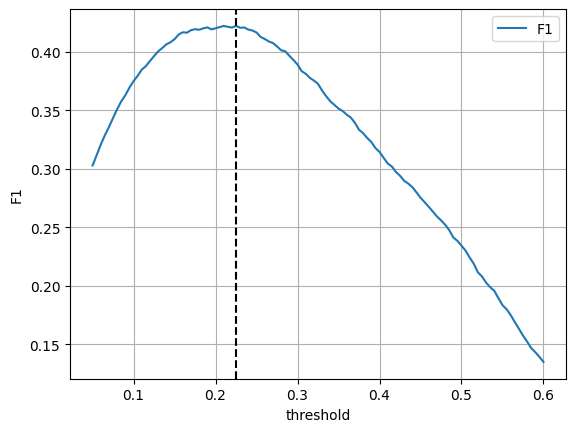

In [102]:
# Choose the decision threshold on the validation set
p_val = sigmoid(x_te @ best_w_1)

def confusion(y, p, t):
    y = y.ravel(); pred = p.ravel() > t
    tp = np.sum(pred & (y == 1))
    fp = np.sum(pred & (y == 0))
    fn = np.sum(~pred & (y == 1))
    tn = np.sum(~pred & (y == 0))
    return tp, fp, fn, tn

def f1_at(y, p, t):
    tp, fp, fn, tn = confusion(y, p, t)
    return 2 * tp / (2 * tp + fp + fn)

thresholds = np.linspace(0.05, 0.6, 111)
f1s_1 = np.array([f1_at(y_te, p_val, t) for t in thresholds])
best_t_1 = thresholds[int(np.argmax(f1s_1))]

print(f"best threshold = {best_t_1:.3f}, F1 = {f1_at(y_te, p_val, best_t_1):.4f}")

tp_1, fp_1, fn_1, tn_1 = confusion(y_te, p_val, best_t_1)

print(f"                   true      false\n\
        negative   {tn_1}      {fn_1}\n\
        positive   {tp_1}      {fp_1}")

precision_1 = tp_1/(tp_1 + fp_1)
recall_1 = tp_1/(tp_1 + fn_1)

print(f"precision = {precision_1:.3f}, recall = {recall_1:.3f}")
print(f"predicted positive rate = {(p_val > best_t_1).mean():.3f} (true rate = {y_te.mean():.3f})")

plt.plot(thresholds, f1s_1, label="F1")
plt.axvline(best_t_1, color="k", linestyle="--")
plt.xlabel("threshold"); plt.ylabel("F1"); plt.legend(); plt.grid(); plt.show()

#### Computing the Confusion Matrix (model WITH interaction terms)

best threshold = 0.200, F1 = 0.4250
                   true      false
        negative   53747      2457
        positive   3206      6217
precision = 0.340, recall = 0.566
predicted positive rate = 0.144 (true rate = 0.086)


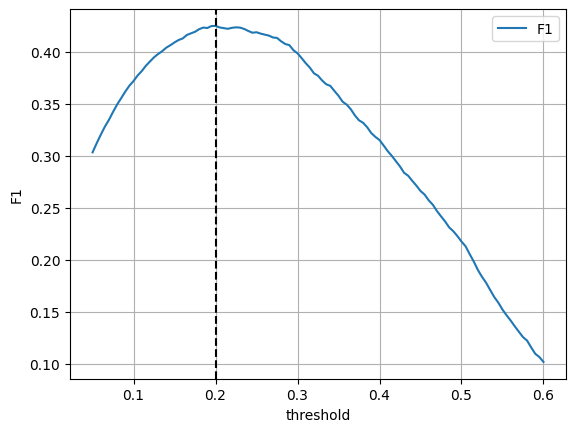

In [103]:
# Choose the decision threshold on the validation set
p_val = sigmoid(X_te @ best_w_2)

f1s_2 = np.array([f1_at(y_te, p_val, t) for t in thresholds])
best_t_2 = thresholds[int(np.argmax(f1s_2))]

print(f"best threshold = {best_t_2:.3f}, F1 = {f1_at(y_te, p_val, best_t_2):.4f}")

tp_2, fp_2, fn_2, tn_2 = confusion(y_te, p_val, best_t_2)

print(f"                   true      false\n\
        negative   {tn_2}      {fn_2}\n\
        positive   {tp_2}      {fp_2}")

precision_2 = tp_2/(tp_2 + fp_2)
recall_2 = tp_2/(tp_2 + fn_2)

print(f"precision = {precision_2:.3f}, recall = {recall_2:.3f}")
print(f"predicted positive rate = {(p_val > best_t_2).mean():.3f} (true rate = {y_te.mean():.3f})")

plt.plot(thresholds, f1s_2, label="F1")
plt.axvline(best_t_2, color="k", linestyle="--")
plt.xlabel("threshold"); plt.ylabel("F1"); plt.legend(); plt.grid(); plt.show()

## Applying the Model to heldout data

In [ ]:
def preprocess_test(x_raw):
    x = replace_sentinels(x_raw, feature_names, rules)
    x = x[:, keep]
    x = np.where(np.isnan(x), median, x)
    x = (x - mean) / std
    return np.c_[np.ones(x.shape[0]), x]

def add_selected_terms(x):
    cols = [(x[:, candidates[k][0]] * x[:, candidates[k][1]] - stats[0][k]) / stats[1][k]
            for k in selected]
    return np.c_[x, np.column_stack(cols)]

xt1 = preprocess_test(x_test) # model 1 features
xt2 = add_selected_terms(xt1) # model 2 features

p1 = sigmoid(xt1 @ best_w_1).ravel()
p2 = sigmoid(xt2 @ best_w_2).ravel()
n = len(x_test)


models = {
    "model 1 (no interactions)": (p1, best_t_1, precision_1, recall_1),
    "model 2 (with interactions)": (p2, best_t_2, precision_2, recall_2)}

for name, (p, t, prec, rec) in models.items():
    flagged = int((p > t).sum())
    print(name)
    print(f"  flagged above threshold : {flagged} ({flagged/n:.1%})")
    print(f"  expected sick (sum of p): {p.sum():.0f} ({p.mean():.1%})")
    print(f"  corrected flagged count : {flagged*prec/rec:.0f}")

model 1 (no interactions)
  flagged above threshold : 12727 (11.6%)
  expected sick (sum of p): 9865 (9.0%)
  corrected flagged count : 9472
model 2 (with interactions)
  flagged above threshold : 15695 (14.3%)
  expected sick (sum of p): 9871 (9.0%)
  corrected flagged count : 9432
